In [2]:
import pandas as pd
df = pd.read_csv("data/fitbit_devices_sold.csv")
df

,year,devices_sold_millions,source
0,2011,0.200,Fitbit S-1 (2015)
1,2012,1.300,Fitbit S-1 (2015)
2,2013,4.500,Fitbit S-1 (2015)
3,2014,10.900,Fitbit S-1 (2015); Fitbit FY2015 10-K
4,2015,21.400,Fitbit FY2015 10-K
5,2016,22.300,Fitbit FY2016 10-K
6,2017,15.343,Fitbit FY2019 10-K
7,2018,13.939,Fitbit FY2019 10-K
8,2019,15.988,Fitbit FY2019 10-K


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Bass model: cumulative adopters N(t) and period sales S(t) = N(t) - N(t-1)
def bass_cum(t, p, q, M):
    e = np.exp(-(p + q) * t)
    return M * (1 - e) / (1 + (q / p) * e)

def bass_sales(t, p, q, M):
    return bass_cum(t, p, q, M) - bass_cum(t - 1, p, q, M)

def fit_bass(t, y):
    popt, pcov = curve_fit(
        bass_sales, t, y,
        p0=(0.03, 0.4, y.sum() * 1.5),
        bounds=([1e-5, 1e-3, y.sum()], [1, 3, 2000]),
        maxfev=50000,
    )
    return popt, np.sqrt(np.diag(pcov))

def r_squared(y, pred):
    return 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()

results = {}
for n, label in [(6, "2011-2016"), (9, "2011-2019")]:
    t = np.arange(1, n + 1)
    y = df["devices_sold_millions"].values[:n]
    popt, se = fit_bass(t, y)
    results[label] = popt
    print(label)
    print(f"  p = {popt[0]:.4f} (se {se[0]:.4f})")
    print(f"  q = {popt[1]:.4f} (se {se[1]:.4f})")
    print(f"  M = {popt[2]:.1f} million (se {se[2]:.1f})")
    print(f"  R2 = {r_squared(y, bass_sales(t, *popt)):.3f}")

    

Matplotlib is building the font cache; this may take a moment.


2011-2016
  p = 0.0026 (se 0.0003)
  q = 1.2122 (se 0.0330)
  M = 80.4 million (se 1.8)
  R2 = 0.999
2011-2019
  p = 0.0118 (se 0.0067)
  q = 0.6746 (se 0.1385)
  M = 121.7 million (se 16.7)
  R2 = 0.821


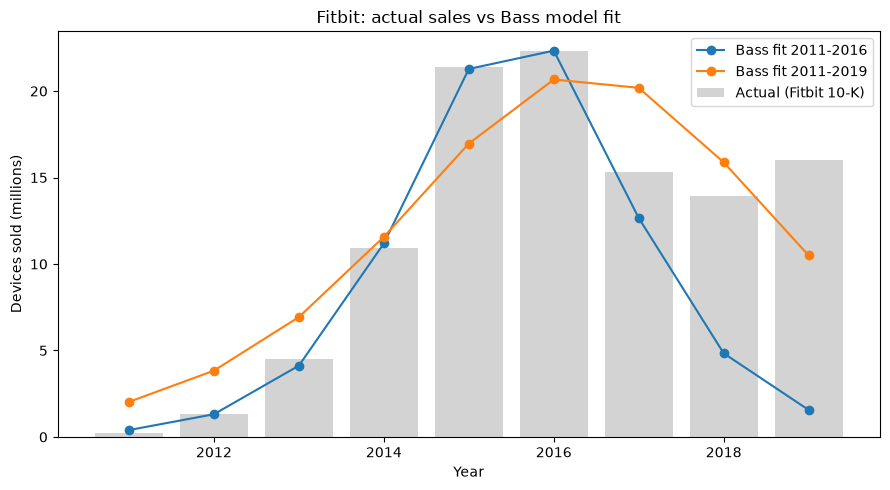

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
years = df["year"].values
ax.bar(years, df["devices_sold_millions"], color="lightgray", label="Actual (Fitbit 10-K)")
tt = np.arange(1, 10)
for label, popt in results.items():
    ax.plot(years, bass_sales(tt, *popt), marker="o", label=f"Bass fit {label}")
ax.set_xlabel("Year")
ax.set_ylabel("Devices sold (millions)")
ax.set_title("Fitbit: actual sales vs Bass model fit")
ax.legend()
plt.tight_layout()
plt.savefig("img/fitbit_bass_fit.png", dpi=200)
plt.show()

In [5]:
   params = pd.DataFrame(results, index=["p", "q", "M_millions"]).T
   params.to_csv("data/fitbit_bass_parameters.csv")
   params

,p,q,M_millions
2011-2016,0.002552,1.212211,80.373692
2011-2019,0.011790,0.674576,121.703258


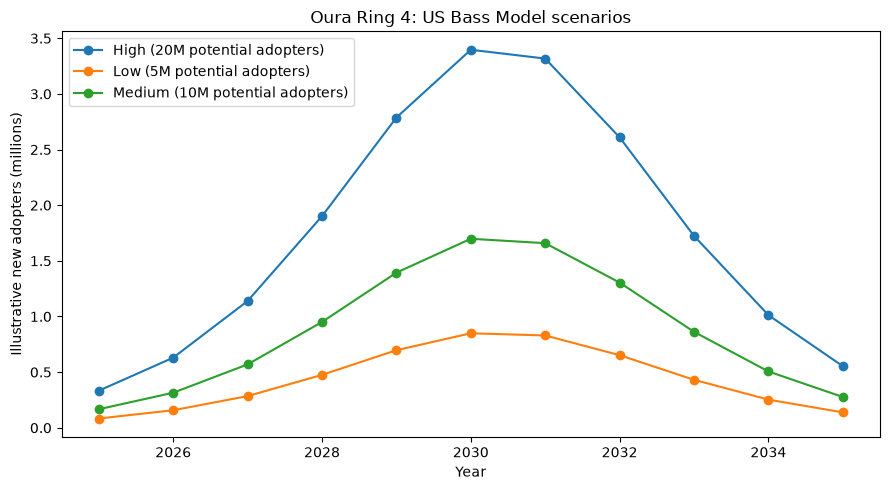

,scenario,year,new_adopters_M,cumulative_adopters_M,market_potential_M
0,Low (5M potential adopters),2025,0.083,0.083,5
1,Low (5M potential adopters),2026,0.158,0.241,5
2,Low (5M potential adopters),2027,0.285,0.526,5
3,Low (5M potential adopters),2028,0.475,1.001,5
4,Low (5M potential adopters),2029,0.697,1.698,5
5,Low (5M potential adopters),2030,0.849,2.547,5
6,Low (5M potential adopters),2031,0.829,3.376,5
7,Low (5M potential adopters),2032,0.652,4.029,5
8,Low (5M potential adopters),2033,0.431,4.460,5
9,Low (5M potential adopters),2034,0.253,4.713,5


In [7]:

# Oura Ring 4: illustrative US Bass Model forecast
# Fitbit parameters are used as an analogy, not Oura-specific estimates.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the longer historical Fitbit fit
p, q, _ = results["2011-2019"]

# Hypothetical US market-size scenarios (millions).
# These are assumptions for sensitivity analysis, not verified estimates.
market_scenarios = {
    "Low (5M potential adopters)": 5,
    "Medium (10M potential adopters)": 10,
    "High (20M potential adopters)": 20,
}

def bass_cumulative(t, p, q, M):
    t = np.asarray(t, dtype=float)
    e = np.exp(-(p + q) * t)
    return M * (1 - e) / (1 + (q / p) * e)

# Ring 4 launched in October 2024; 2025 is the first full calendar year.
years = np.arange(2025, 2036)
t = np.arange(1, len(years) + 1)

frames = []

for scenario, M in market_scenarios.items():
    cumulative = bass_cumulative(t, p, q, M)
    previous = bass_cumulative(t - 1, p, q, M)

    frames.append(pd.DataFrame({
        "scenario": scenario,
        "year": years,
        "new_adopters_M": cumulative - previous,
        "cumulative_adopters_M": cumulative,
        "market_potential_M": M,
    }))

forecast = pd.concat(frames, ignore_index=True)

forecast.to_csv("data/oura_us_forecast.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))

for scenario, group in forecast.groupby("scenario"):
    ax.plot(
        group["year"],
        group["new_adopters_M"],
        marker="o",
        label=scenario,
    )

ax.set_xlabel("Year")
ax.set_ylabel("Illustrative new adopters (millions)")
ax.set_title("Oura Ring 4: US Bass Model scenarios")
ax.legend()
plt.tight_layout()
plt.savefig("img/oura_us_forecast.png", dpi=200)
plt.show()

forecast.round(3)
